In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
from plotly.offline import plot
import plotly.express as px
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from utils import save_plotly_figure_as_html
from ex_01_read_data import get_welding_data
from ex_03_feature_extraction import extract_features
from ex_04_my_kmeans import MyKMeans


In [2]:
data_path = Path("data.csv")
plot_path = Path("plots/ex_04")
plot_path.mkdir(parents=True, exist_ok=True)


data, labels, exp_ids = get_welding_data(data_path, n_samples=5_000)

## Exercise 4.2: Optimal Cluster Selection

Implement the elbow method to find the optimal number of clusters for the raw time series data using your implement of the kmeans algorithm (MyKMeans).

1. Calculate the distortion (inertia) for different values of k (1 to 10)
2. Plot the results to identify the "elbow point" with matplotlib where adding more clusters produces diminishing returns
3. This will help determine the most appropriate number of clusters for our welding data

k=1: inertia=21064.2593
k=2: inertia=15080.6900
k=3: inertia=9639.7808
k=4: inertia=8918.1272
k=5: inertia=6718.6493
k=6: inertia=6193.9733
k=7: inertia=5779.9740
k=8: inertia=5342.7906
k=9: inertia=5155.8833
k=10: inertia=4878.9823


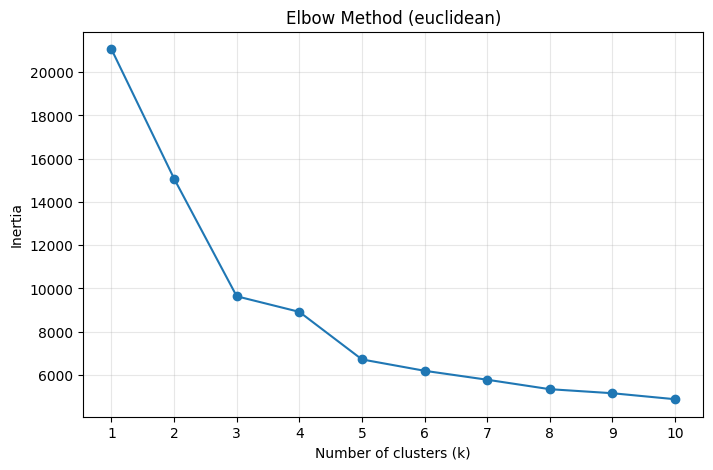

[21064.25925438907,
 15080.690049399655,
 9639.780759905887,
 8918.127154044243,
 6718.649346842957,
 6193.973320067373,
 5779.973999061034,
 5342.790615325024,
 5155.883251618579,
 4878.982336577284]

In [ ]:
def elbow_method(X, max_clusters=10, distance_metric="euclidean"):
    X = np.asarray(X, dtype=float)

    # Scale the input data
    if X.ndim == 3:
        original_shape = X.shape

        X_scaled = MinMaxScaler().fit_transform(
            X.reshape(-1, X.shape[-1])
        ).reshape(original_shape)

    elif X.ndim == 2:
        X_scaled = MinMaxScaler().fit_transform(X)

    else:
        raise ValueError("X must be a 2D or 3D array")

    inertias = []
    max_clusters = min(max_clusters, len(X_scaled))

    # Calculate inertia for different numbers of clusters
    for k in range(1, max_clusters + 1):

        model = MyKMeans(
            k=k,
            distance_metric=distance_metric,
            init_method="kmeans++"
        )

        model.fit(X_scaled)

        # Get distances between samples and cluster centroids
        if model.centroids is None:
            raise RuntimeError(
                "MyKMeans.fit() did not initialize centroids. "
                "Check that the updated class is loaded."
            )

        distances = np.asarray(
            model._compute_distance(X_scaled, model.centroids)
        )

        # Find the nearest centroid for each sample
        labels = np.argmin(distances, axis=1)

        # Calculate inertia: sum of squared distances
        inertia = float(
            np.sum(
                distances[np.arange(len(X_scaled)), labels] ** 2
            )
        )

        inertias.append(inertia)

        print(f"k={k}: inertia={inertia:.4f}")

    # Plot elbow curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, max_clusters + 1),
        inertias,
        marker="o"
    )

    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Inertia")
    plt.title(f"Elbow Method ({distance_metric})")
    plt.xticks(range(1, max_clusters + 1))
    plt.grid(True, alpha=0.3)
    plt.show()

    return inertias

elbow_method(data)

## Exercise 4.3: Clustering with MyKMeans

### Based on the elbow curve above, explain your choice of k:

1. What does the shape of the elbow curve tell you about the underlying data structure?
2. Why did you select this specific number of clusters?
   - Consider the plot and the elbow method to justify your choice
   - How might this choice affect the interpretability of the resulting clusters?

### KMeans with euclidean distance and dtw distance
1. run K means with you selected k 


In [ ]:
n_clusters = 4

# Scale current and voltage while preserving the time-series shape
data_scaled = MinMaxScaler().fit_transform(
    data.reshape(-1, data.shape[-1])
).reshape(data.shape)

# Euclidean distance
kmeans_euclidean = MyKMeans(
    k=n_clusters,
    distance_metric="euclidean",
    init_method="kmeans++"
)

clusters_euclidean = kmeans_euclidean.fit_predict(data_scaled)

print("Euclidean clustering:")
print("Cluster sizes:", np.bincount(clusters_euclidean))
print("Inertia:", kmeans_euclidean.inertia_)

# DTW is computationally expensive, so use a subset initially.
dtw_samples = min(200, len(data_scaled))
data_dtw = data_scaled[:dtw_samples]

kmeans_dtw = MyKMeans(
    k=n_clusters,
    max_iter=20,
    distance_metric="dtw",
    init_method="kmeans++"
)

clusters_dtw = kmeans_dtw.fit_predict(data_dtw)

print("\nDTW clustering:")
print("Cluster sizes:", np.bincount(clusters_dtw))
print("Inertia:", kmeans_dtw.inertia_)

Euclidean clustering:
Cluster sizes: [3184 1263  403  150]
Inertia: 8918.155175608235

DTW clustering:
Cluster sizes: [108  22   8  62]
Inertia: 85.11283948398776


## Exercise 4.4: Cluster Visualization

Plot the mean time series (centroids) for each cluster to visualize and understand the patterns.

Remember that our welding data has both current and voltage measurements over time (shape: n_samples, sequence_length, features). For each cluster:
1. Plot the average current pattern
2. Plot the average voltage pattern
3. Look for distinctive characteristics in each cluster that might relate to welding quality

This visualization will help identify what makes each cluster unique in terms of temporal patterns.

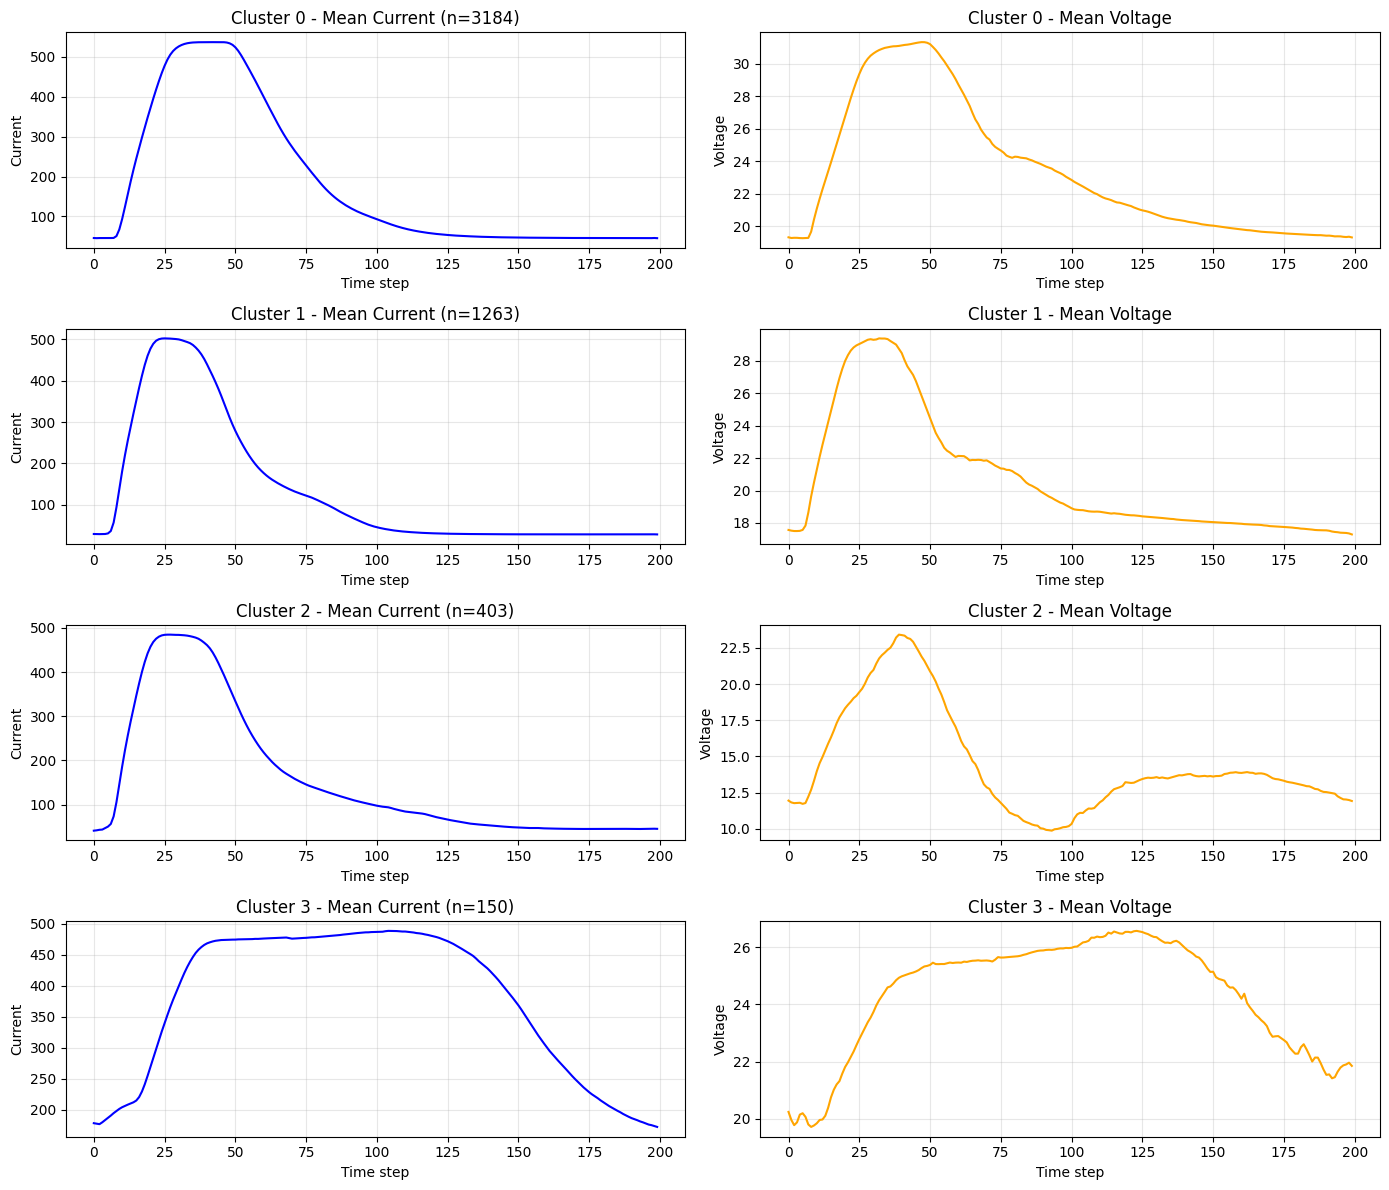

In [5]:
fig, axes = plt.subplots(
    n_clusters, 2,
    figsize=(14, 3 * n_clusters)
)

for cluster_id in range(n_clusters):

    cluster_data = data[clusters_euclidean == cluster_id]

    if len(cluster_data) == 0:
        continue

    # Calculate the mean time series for the cluster
    mean_series = cluster_data.mean(axis=0)

    # Current
    axes[cluster_id, 0].plot(
        mean_series[:, 0],
        color="blue"
    )
    axes[cluster_id, 0].set_title(
        f"Cluster {cluster_id} - Mean Current (n={len(cluster_data)})"
    )
    axes[cluster_id, 0].set_xlabel("Time step")
    axes[cluster_id, 0].set_ylabel("Current")
    axes[cluster_id, 0].grid(True, alpha=0.3)

    # Voltage
    axes[cluster_id, 1].plot(
        mean_series[:, 1],
        color="orange"
    )
    axes[cluster_id, 1].set_title(
        f"Cluster {cluster_id} - Mean Voltage"
    )
    axes[cluster_id, 1].set_xlabel("Time step")
    axes[cluster_id, 1].set_ylabel("Voltage")
    axes[cluster_id, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Exercise 4.5: Feature-Based Clustering

Now we'll use the engineered features extracted in Exercise 3 instead of raw time series data. Therefore, you can use the euclidean distance metric.

1. Load your extracted features from exercise 3 
2. Split them into data and labels
3. Scale the data for better clustering performance
4. Apply the elbow method again to determine the optimal number of clusters for the feature-based approach
5. Compare this result with the clustering of raw time series data. Consider why the optimal k might differ between the two approaches:
   - Do engineered features represent the data differently?
   - Which approach might better capture the relevant patterns for quality assessment?


Feature columns: ['current_mean', 'current_std', 'current_min', 'current_max', 'current_median', 'current_peak_to_peak', 'current_rms', 'current_variance', 'current_energy', 'current_dominant_frequency', 'voltage_mean', 'voltage_std', 'voltage_min', 'voltage_max', 'voltage_median', 'voltage_peak_to_peak', 'voltage_rms', 'voltage_variance', 'voltage_energy', 'voltage_dominant_frequency', 'labels']
Feature matrix shape: (5000, 20)
k=1: inertia=1370.6912
k=2: inertia=778.4657
k=3: inertia=566.6954
k=4: inertia=453.3235
k=5: inertia=446.7094
k=6: inertia=353.4236
k=7: inertia=354.3481
k=8: inertia=288.7640
k=9: inertia=293.6559
k=10: inertia=289.0622


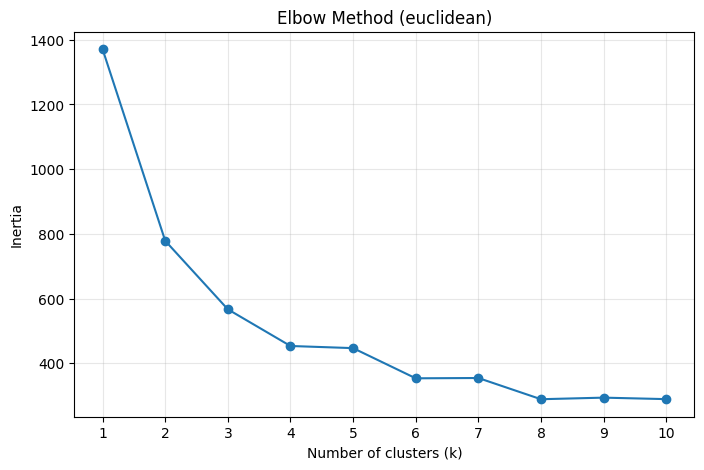


Feature-based clustering results:
Number of clusters: 3
Cluster sizes: [ 130 2779 2091]
Inertia: 566.6953689022894
Feature clustering ARI: 0.1121769040049792


In [ ]:
features = extract_features(data, labels)

print("Feature columns:", features.columns.tolist())

# Separate features from labels
label_column = "labels" if "labels" in features.columns else "label"

feature_labels = features[label_column].to_numpy()
feature_X = features.drop(columns=[label_column])

# Scale extracted features
feature_scaled = MinMaxScaler().fit_transform(feature_X)

print("Feature matrix shape:", feature_scaled.shape)

# Apply elbow method to extracted features
feature_inertias = elbow_method(
    feature_scaled,
    max_clusters=10,
    distance_metric="euclidean"
)

# Generate cluster counts matching the elbow results
feature_ks = np.arange(1, len(feature_inertias) + 1)

# Select k based on the feature elbow plot
feature_k = 3

# Apply custom K-Means
feature_model = MyKMeans(
    k=feature_k,
    distance_metric="euclidean",
    init_method="kmeans++"
)

feature_clusters = feature_model.fit_predict(feature_scaled)

# Evaluate clustering using Adjusted Rand Index
ari = adjusted_rand_score(feature_labels, feature_clusters)

print("\nFeature-based clustering results:")
print("Number of clusters:", feature_k)
print("Cluster sizes:", np.bincount(feature_clusters))
print("Inertia:", feature_model.inertia_)
print("Feature clustering ARI:", ari)


## Exercise 4.6: Advanced 3D Visualization

Visualize the clustering results using interactive 3D plots with Plotly.

1. Use PCA to reduce the dimensionality of our feature space to 3 components
2. Create two visualizations:
   - Points colored by assigned cluster
   - Same points colored by actual quality labels
3. Include the explained variance for each principal component in the axis labels
4. Save the figures to the plot_path


This visualization will help us understand how well our clustering approach aligns with the known quality designations.

#### Note:
- You can use the following links to find more information about the PCA:
   - https://en.wikipedia.org/wiki/Principal_component_analysis
   - https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html


In [7]:
pca = PCA(n_components=3)
components = pca.fit_transform(feature_scaled)
variance = pca.explained_variance_ratio_ * 100
axis_labels = {f'PC{i+1}': f'PC{i+1} ({variance[i]:.1f}% explained)' for i in range(3)}
plot_data = pd.DataFrame(components, columns=['PC1', 'PC2', 'PC3'])
plot_data['cluster'] = feature_clusters.astype(str)
plot_data['quality'] = feature_labels.astype(str)
fig1 = px.scatter_3d(plot_data, x='PC1', y='PC2', z='PC3', color='cluster',
                     labels=axis_labels, title='PCA: engineered-feature clusters')
fig2 = px.scatter_3d(plot_data, x='PC1', y='PC2', z='PC3', color='quality',
                     labels=axis_labels, title='PCA: true quality labels')
save_plotly_figure_as_html(fig1, plot_path / f'clusters_3d_{feature_k}_clusters')
save_plotly_figure_as_html(fig2, plot_path / f'quality_3d_{feature_k}_clusters')
fig1.show()
fig2.show()

## Exercise 4.7: Analysis and Interpretation

Analyze the clustering results in depth and discuss their implications:

1. Cluster separation:
   - How well do clusters separate different quality levels?
   - What is the Adjusted Rand Index between clusters and quality labels?
   - Are there clusters that predominantly contain good or bad welds?

2. Feature importance:
   - Which features seem most important for distinguishing clusters?
   - How does the PCA visualization help us understand the data structure?

3. Process insights:
   - What insights could these clusters provide for improving the welding process?
   - Could certain clusters identify specific types of welding issues?

4. Limitations:
   - What are the limitations of using clustering for quality assessment?
   - How might the approach be improved in future iterations?



In [ ]:
# Adjusted Rand Index (ARI)
print(
    'ARI (raw Euclidean):',
    adjusted_rand_score(labels, clusters_euclidean)
)

print(
    'ARI (feature Euclidean):',
    adjusted_rand_score(feature_labels, feature_clusters)
)

# Cluster vs quality counts
print('\nCluster vs quality counts:')

print(
    pd.crosstab(
        pd.Series(feature_clusters, name='cluster'),
        pd.Series(feature_labels, name='quality')
    )
)

# PCA feature importance
importance = pd.Series(
    np.abs(pca.components_[0]),
    index=feature_X.columns
)

print('\nLargest absolute PC1 loadings:')

print(
    importance.sort_values(ascending=False).head(10)
)


ARI (raw Euclidean): 0.11346265867631622
ARI (feature Euclidean): 0.1121769040049792

Cluster vs quality counts:
quality     0     1
cluster            
0          97    33
1        1983   796
2         791  1300

Largest absolute PC1 loadings:
voltage_min                   0.750642
voltage_peak_to_peak          0.281413
voltage_energy                0.280193
voltage_mean                  0.243309
voltage_rms                   0.207034
voltage_median                0.206637
voltage_std                   0.200859
voltage_variance              0.156500
voltage_dominant_frequency    0.145764
current_min                   0.105642
dtype: float64
